| **Inicio**         | **atrás 2**                          | **Siguiente 4**                                    |
| ------------------ | ------------------------------------ | -------------------------------------------------- |
| [🏠](../README.md) | [⏪](./4_2_Derivadas_parciales.ipynb) | [⏩](./4_4_Hessiano.ipynb) |

# Jacobiano para Scientific Machine Learning

El **Jacobiano** es uno de los conceptos más importantes del cálculo multivariable para SciML. No debes verlo simplemente como "una matriz de derivadas": el Jacobiano es la herramienta que permite **aproximar funciones no lineales mediante transformaciones lineales**, estudiar sensibilidad, resolver sistemas no lineales, analizar ODEs, construir métodos de Newton y calcular derivadas mediante autodiferenciación.

La idea central es:

$$
\boxed{
\text{función no lineal}
\quad\longrightarrow\quad
\text{Jacobiano}
\quad\longrightarrow\quad
\text{aproximación lineal}
}
$$

Y posteriormente:

$$
\boxed{
J
\rightarrow
\text{Newton}
\rightarrow
\text{ODE/PDE}
\rightarrow
\text{sensibilidad}
\rightarrow
\text{PINNs/SciML}
}
$$

# 1. ¿Qué problema resuelve el Jacobiano?

Hasta ahora has visto funciones como:

$$
f(x,y)
$$

donde:

$$
f:\mathbb R^2\rightarrow\mathbb R
$$

Por ejemplo:

$$
f(x,y)=x^2+3xy+y^2
$$

Para esta función utilizamos el gradiente:

$$
\nabla f=
\begin{bmatrix}
f_x\\
f_y
\end{bmatrix}
$$

Pero ahora imagina que tenemos **varias salidas**:

$$
F(x,y)=
\begin{bmatrix}
F_1(x,y)\\
F_2(x,y)
\end{bmatrix}
$$

Ahora necesitamos saber cómo cambia **cada salida respecto a cada entrada**.

Eso es exactamente lo que organiza el Jacobiano.

# 2. Definición

Sea:

$$
F:\mathbb R^n\rightarrow\mathbb R^m
$$

con:

$$
F(x_1,\ldots,x_n)
=
\begin{bmatrix}
F_1(x_1,\ldots,x_n)\\
F_2(x_1,\ldots,x_n)\\
\vdots\\
F_m(x_1,\ldots,x_n)
\end{bmatrix}
$$

El Jacobiano es:

$$
\boxed{
J_F=
\begin{bmatrix}
\frac{\partial F_1}{\partial x_1}
&
\frac{\partial F_1}{\partial x_2}
&
\cdots
&
\frac{\partial F_1}{\partial x_n}
\\
\frac{\partial F_2}{\partial x_1}
&
\frac{\partial F_2}{\partial x_2}
&
\cdots
&
\frac{\partial F_2}{\partial x_n}
\\
\vdots
&
\vdots
&
\ddots
&
\vdots
\\
\frac{\partial F_m}{\partial x_1}
&
\frac{\partial F_m}{\partial x_2}
&
\cdots
&
\frac{\partial F_m}{\partial x_n}
\end{bmatrix}
}
$$

Por tanto:

$$
\boxed{J_F\in\mathbb R^{m\times n}}
$$

# 3. Regla que debes memorizar

Esta es muy importante:

> **Las filas corresponden a las salidas y las columnas a las entradas.**

Si:

$$
F:\mathbb R^3\rightarrow\mathbb R^2
$$

entonces:

$$
J_F
$$

tendrá:

$$
2\times3
$$

porque hay:

* 2 salidas;
* 3 entradas.

# 4. Ejemplo sencillo

Supongamos:

$$
F(x,y)=
\begin{bmatrix}
x^2+y\\
3x-y^2
\end{bmatrix}
$$

Tenemos:

$$
F_1=x^2+y
$$

y:

$$
F_2=3x-y^2
$$

Calculamos todas las derivadas.

Para $(F_1)$:

$$
\frac{\partial F_1}{\partial x}=2x
$$

$$
\frac{\partial F_1}{\partial y}=1
$$

Para $(F_2)$:

$$
\frac{\partial F_2}{\partial x}=3
$$

$$
\frac{\partial F_2}{\partial y}=-2y
$$

Entonces:

$$
\boxed{
J_F(x,y)=
\begin{bmatrix}
2x&1\\
3&-2y
\end{bmatrix}
}
$$

# 5. ¿Qué significa físicamente?

Supongamos que:

$$
x=\text{temperatura}
$$

y:

$$
y=\text{presión}
$$

mientras que:

$$
F_1=\text{densidad}
$$

y:

$$
F_2=\text{velocidad}.
$$

Entonces:

$$
J=
\begin{bmatrix}
\frac{\partial \rho}{\partial T}
&
\frac{\partial \rho}{\partial P}
\\
\frac{\partial v}{\partial T}
&
\frac{\partial v}{\partial P}
\end{bmatrix}
$$

Cada elemento responde una pregunta de sensibilidad:

$$
\frac{\partial \rho}{\partial T}
$$

> ¿Cuánto cambia la densidad si modifico la temperatura?

Mientras:

$$
\frac{\partial v}{\partial P}
$$

responde:

> ¿Cuánto cambia la velocidad si modifico la presión?

Por eso el Jacobiano es fundamental para **análisis de sensibilidad**.

# 6. Jacobiano como transformación lineal

Esta es probablemente la interpretación más importante.

Supongamos:

$$
F:\mathbb R^n\rightarrow\mathbb R^m
$$

y estamos cerca de un punto:

$$
\mathbf x_0.
$$

Para un pequeño desplazamiento:

$$
\Delta x
$$

podemos aproximar:

$$
\boxed{
F(\mathbf x_0+\Delta\mathbf x)
\approx
F(\mathbf x_0)
+
J_F(\mathbf x_0)\Delta\mathbf x
}
$$

Esta ecuación es fundamental.

El Jacobiano convierte un pequeño cambio en las entradas:

$$
\Delta\mathbf x
$$

en un pequeño cambio en las salidas:

$$
\Delta\mathbf F.
$$

Es decir:

$$
\boxed{
\Delta F\approx J\Delta x
}
$$

# 7. Ejemplo numérico

Consideremos:

$$
F(x,y)=
\begin{bmatrix}
x^2+y^2\\
e^x+\sin y
\end{bmatrix}
$$

El Jacobiano es:

$$
J=
\begin{bmatrix}
2x&2y\\
e^x&\cos y
\end{bmatrix}
$$

Tomemos:

$$
(x_0,y_0)=(1,\pi/4)
$$

Entonces:

$$
J(1,\pi/4)
=
\begin{bmatrix}
2&\pi/2\\
e&\sqrt2/2
\end{bmatrix}
$$

Ahora supongamos un pequeño cambio:

$$
\Delta x=
\begin{bmatrix}
0.01\\
-0.02
\end{bmatrix}.
$$

Entonces:

$$
\Delta F
\approx
J\Delta x.
$$

Calculamos:

$$
\Delta F
\approx
\begin{bmatrix}
2&1.5708\\
2.7183&0.7071
\end{bmatrix}
\begin{bmatrix}
0.01\\
-0.02
\end{bmatrix}
$$

Primera componente:

$$
2(0.01)+1.5708(-0.02)
$$

$$
=0.02-0.031416
$$

$$
\approx-0.011416
$$

Segunda:

$$
2.7183(0.01)+0.7071(-0.02)
$$

$$
\approx0.027183-0.014142
$$

$$
\approx0.013041
$$

Por tanto:

$$
\boxed{
\Delta F\approx
\begin{bmatrix}
-0.011416\\
0.013041
\end{bmatrix}
}
$$

El Jacobiano acaba de convertir una pequeña perturbación de entrada en una aproximación de la perturbación de salida.

# 8. Python: verificar la aproximación

In [1]:
import numpy as np

def F(x, y):
    return np.array([
        x**2 + y**2,
        np.exp(x) + np.sin(y)
    ])

def J(x, y):
    return np.array([
        [2*x, 2*y],
        [np.exp(x), np.cos(y)]
    ])

# Punto
x0 = 1.0
y0 = np.pi / 4

# Perturbación
dx = np.array([
    0.01,
    -0.02
])

x1 = np.array([x0, y0]) + dx

# Cambio real
delta_real = F(x1[0], x1[1]) - F(x0, y0)

# Aproximación de primer orden
delta_linear = J(x0, y0) @ dx

print("Cambio real:")
print(delta_real)

print("\nCambio aproximado por Jacobiano:")
print(delta_linear)

print("\nError:")
print(np.linalg.norm(delta_real - delta_linear))

Cambio real:
[-0.01091593  0.01303658]

Cambio aproximado por Jacobiano:
[-0.01141593  0.01304068]

Error:
0.000500016855493001


Una cosa muy importante que debes observar:

$$
\boxed{
\text{el error disminuye cuando }\|\Delta x\|\rightarrow0
}
$$

Esto es precisamente lo que significa que la función sea localmente aproximable mediante una transformación lineal.

# 9. Ejemplo difícil: sistema no lineal

Ahora vamos a trabajar con un ejemplo más cercano a problemas científicos.

Sea:

$$
F(x,y,z)=
\begin{bmatrix}
x^2+yz\\
e^x+\sin(yz)\\
xyz+x^3
\end{bmatrix}
$$

Tenemos:

$$
F_1=x^2+yz
$$

$$
F_2=e^x+\sin(yz)
$$

$$
F_3=xyz+x^3
$$

## Derivadas de $(F_1)$

$$
\frac{\partial F_1}{\partial x}=2x
$$

$$
\frac{\partial F_1}{\partial y}=z
$$

$$
\frac{\partial F_1}{\partial z}=y
$$

## Derivadas de $(F_2)$

$$
\frac{\partial F_2}{\partial x}=e^x
$$

$$
\frac{\partial F_2}{\partial y}
=
z\cos(yz)
$$

$$
\frac{\partial F_2}{\partial z}
=
y\cos(yz)
$$

## Derivadas de $(F_3)$

$$
\frac{\partial F_3}{\partial x}
=
yz+3x^2
$$

$$
\frac{\partial F_3}{\partial y}
=
xz
$$

$$
\frac{\partial F_3}{\partial z}
=
xy
$$

Por tanto:

$$
\boxed{
J_F=
\begin{bmatrix}
2x&z&y\\
e^x&z\cos(yz)&y\cos(yz)\\
yz+3x^2&xz&xy
\end{bmatrix}
}
$$

Este es el tipo de Jacobiano que aparecerá en problemas científicos reales.

# 10. Jacobiano y gradiente: no son lo mismo

Esta distinción es importantísima.

Si:

$$
f:\mathbb R^n\rightarrow\mathbb R
$$

tenemos una sola salida.

El gradiente es:

$$
\nabla f=
\begin{bmatrix}
f_{x_1}\\
f_{x_2}\\
\vdots\\
f_{x_n}
\end{bmatrix}.
$$

Pero el Jacobiano, siguiendo la convención que estamos utilizando, sería:

$$
J_f=
\begin{bmatrix}
f_{x_1}&f_{x_2}&\cdots&f_{x_n}
\end{bmatrix}.
$$

Es decir:

$$
\boxed{
J_f=(\nabla f)^T
}
$$

si el gradiente se considera vector columna.

# 11. Una manera de visualizarlo

Tenemos:

$$
f:\mathbb R^n\rightarrow\mathbb R
$$

### Gradiente

$$
\nabla f
$$

te dice:

> ¿En qué dirección cambia más rápidamente la salida?

Pero:

$$
F:\mathbb R^n\rightarrow\mathbb R^m
$$

tiene múltiples salidas.

Entonces:

$$
J_F
$$

te dice:

> ¿Cómo afecta cada variable de entrada a cada salida?

# 12. Jacobiano y sistemas dinámicos

Aquí comienza una conexión **muy importante con SciML**.

Supongamos una ODE:

$$
\boxed{
\frac{d\mathbf u}{dt}=F(\mathbf u,t)
}
$$

donde:

$$
\mathbf u=
\begin{bmatrix}
u_1\\
u_2\\
\vdots\\
u_n
\end{bmatrix}.
$$

El Jacobiano respecto a $(\mathbf u)$ es:

$$
\boxed{
J_F=
\frac{\partial F}{\partial\mathbf u}
}
$$

con:

$$
(J_F)_{ij}
=
\frac{\partial F_i}{\partial u_j}.
$$

Esto describe cómo una pequeña perturbación del estado modifica la dinámica.

# 13. Ejemplo: sistema depredador-presa

Consideremos el modelo Lotka-Volterra:

$$
\frac{dx}{dt}
=
\alpha x-\beta xy
$$

$$
\frac{dy}{dt}
=
\delta xy-\gamma y
$$

donde:

* $(x)$ = población de presas;
* $(y)$ = población de depredadores.

Definimos:

$$
F(x,y)=
\begin{bmatrix}
\alpha x-\beta xy\\
\delta xy-\gamma y
\end{bmatrix}.
$$

El Jacobiano es:

$$
\boxed{
J_F=
\begin{bmatrix}
\alpha-\beta y&-\beta x\\
\delta y&\delta x-\gamma
\end{bmatrix}
}
$$

Observa el significado.

Por ejemplo:

$$
\frac{\partial F_1}{\partial y}
=
-\beta x
$$

dice cuánto cambia la tasa de crecimiento de las presas cuando modificamos la cantidad de depredadores.

# 14. Python: campo vectorial y Jacobiano

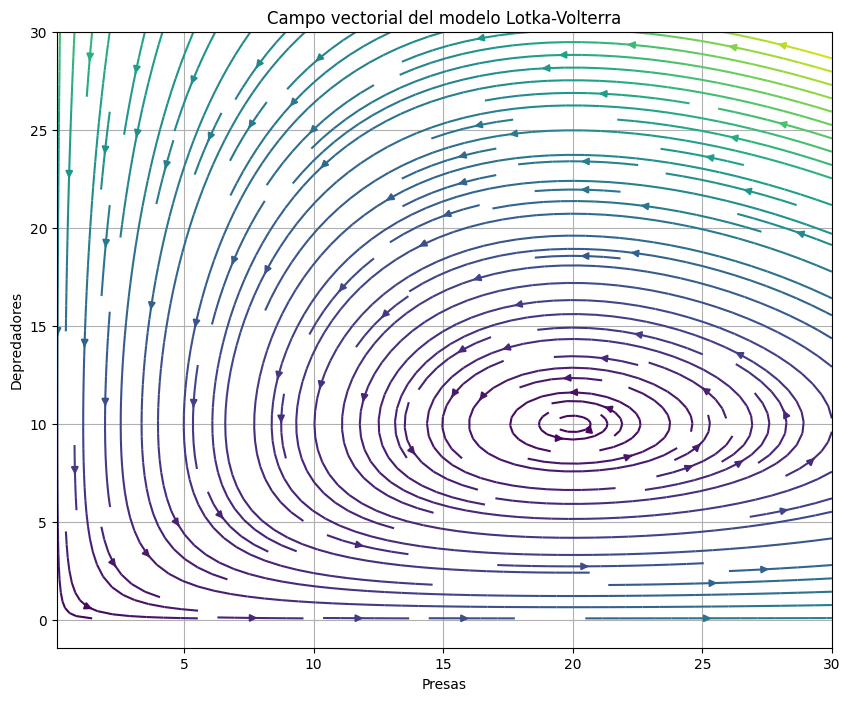

In [2]:
import numpy as np
import matplotlib.pyplot as plt

alpha = 1.0
beta = 0.1
delta = 0.075
gamma = 1.5

x = np.linspace(0.1, 30, 20)
y = np.linspace(0.1, 30, 20)

X, Y = np.meshgrid(x, y)

dX = alpha*X - beta*X*Y
dY = delta*X*Y - gamma*Y

speed = np.sqrt(dX**2 + dY**2)

plt.figure(figsize=(10, 8))

plt.streamplot(
    X, Y,
    dX, dY,
    color=speed,
    density=1.5
)

plt.xlabel("Presas")
plt.ylabel("Depredadores")
plt.title("Campo vectorial del modelo Lotka-Volterra")

plt.grid()

plt.show()

Aquí:

$$
F(x,y)
$$

es un campo vectorial.

El Jacobiano describe cómo cambia ese campo localmente.

# 15. Jacobiano y estabilidad

Supongamos:

$$
\frac{d\mathbf u}{dt}=F(\mathbf u)
$$

y tenemos un punto de equilibrio:

$$
F(\mathbf u^*)=0.
$$

Cerca del equilibrio podemos hacer una aproximación:

$$
F(\mathbf u)
\approx
F(\mathbf u^*)
+
J_F(\mathbf u^*)
(\mathbf u-\mathbf u^*)
$$

Como:

$$
F(\mathbf u^*)=0
$$

queda:

$$
\boxed{
F(\mathbf u)
\approx
J_F(\mathbf u^*)
(\mathbf u-\mathbf u^*)
}
$$

Por tanto, si definimos:

$$
\delta\mathbf u=\mathbf u-\mathbf u^*
$$

tenemos:

$$
\boxed{
\frac{d\delta\mathbf u}{dt}
\approx
J_F(\mathbf u^*)\delta\mathbf u
}
$$

¡Aparece una ecuación lineal!

Esto es fundamental para estudiar la estabilidad de sistemas no lineales.

# 16. Eigenvalores del Jacobiano

Ahora aparece una conexión con lo que ya estudiaste:

$$
Jv=\lambda v.
$$

Los eigenvalores del Jacobiano alrededor de un equilibrio nos indican el comportamiento local.

Si:

$$
\operatorname{Re}(\lambda_i)<0
$$

para todos los eigenvalores:

$$
\boxed{\text{equilibrio localmente asintóticamente estable}}
$$

Si existe algún:

$$
\operatorname{Re}(\lambda_i)>0
$$

entonces existe una dirección localmente inestable.

Así:

$$
\boxed{
\text{Jacobiano}
\rightarrow
\text{eigenvalores}
\rightarrow
\text{estabilidad}
}
$$

Esto es muy importante en dinámica, control, ODEs y SciML.

# 17. Newton para sistemas no lineales

Otra aplicación fundamental.

Supongamos que queremos resolver:

$$
F(\mathbf x)=0.
$$

Para una función escalar conoces Newton:

$$
x_{k+1}
=
x_k-\frac{f(x_k)}{f'(x_k)}.
$$

Para varias variables, reemplazamos:

$$
f'(x)
$$

por el Jacobiano:

$$
J_F(x).
$$

La fórmula se convierte en:

$$
\boxed{
\mathbf x_{k+1}
=
\mathbf x_k
-
J_F(\mathbf x_k)^{-1}F(\mathbf x_k)
}
$$

Pero **computacionalmente no debes calcular explícitamente la inversa**.

En lugar de eso resolvemos:

$$
\boxed{
J_F(\mathbf x_k)\Delta\mathbf x
=
-F(\mathbf x_k)
}
$$

y luego:

$$
\boxed{
\mathbf x_{k+1}
=
\mathbf x_k+\Delta\mathbf x
}
$$

Esto conecta directamente con álgebra lineal numérica.

# 18. Ejemplo de Newton multidimensional

Consideremos:

$$
F_1(x,y)=x^2+y^2-4
$$

$$
F_2(x,y)=e^x+y-1
$$

Queremos encontrar:

$$
F(x,y)=0.
$$

El Jacobiano es:

$$
\boxed{
J=
\begin{bmatrix}
2x&2y\\
e^x&1
\end{bmatrix}
}
$$

En cada iteración:

$$
J(x_k,y_k)\Delta x=-F(x_k,y_k)
$$

y:

$$
x_{k+1}=x_k+\Delta x.
$$

# 19. Implementación desde cero en Python

In [3]:
import numpy as np

def F(x):
    x1, x2 = x

    return np.array([
        x1**2 + x2**2 - 4,
        np.exp(x1) + x2 - 1
    ])


def J(x):
    x1, x2 = x

    return np.array([
        [2*x1, 2*x2],
        [np.exp(x1), 1]
    ])


x = np.array([
    1.0,
    1.0
])

for k in range(20):

    Fx = F(x)
    Jx = J(x)

    # Resolver J Δx = -F
    delta = np.linalg.solve(
        Jx,
        -Fx
    )

    x = x + delta

    print(
        f"Iteración {k+1}: "
        f"x = {x}, "
        f"||F|| = {np.linalg.norm(F(x)):.3e}"
    )

    if np.linalg.norm(F(x)) < 1e-10:
        break

Iteración 1: x = [-1.16395341  4.16395341], ||F|| = 1.510e+01
Iteración 2: x = [-4.05668035  1.59100263], ||F|| = 1.500e+01
Iteración 3: x = [-2.45878419  0.95503983], ||F|| = 2.958e+00
Iteración 4: x = [-1.89191979  0.86597216], ||F|| = 3.297e-01
Iteración 5: x = [-1.81769187  0.8380257 ], ||F|| = 6.305e-03
Iteración 6: x = [-1.81626463  0.83736806], ||F|| = 2.475e-06
Iteración 7: x = [-1.81626407  0.8373678 ], ||F|| = 3.819e-13


Observa que estamos usando:

```python
np.linalg.solve()
```

y no:

```python
np.linalg.inv(J)
```

Esto es mejor numéricamente.

# 20. Jacobiano como matriz de sensibilidad

Supongamos:

$$
F:
\begin{bmatrix}
\text{temperatura}\\
\text{presión}\\
\text{velocidad}
\end{bmatrix}
\rightarrow
\begin{bmatrix}
\text{densidad}\\
\text{viscosidad}
\end{bmatrix}.
$$

Entonces:

$$
J=
\begin{bmatrix}
\frac{\partial\rho}{\partial T}
&
\frac{\partial\rho}{\partial P}
&
\frac{\partial\rho}{\partial v}
\\
\frac{\partial\mu}{\partial T}
&
\frac{\partial\mu}{\partial P}
&
\frac{\partial\mu}{\partial v}
\end{bmatrix}.
$$

Una entrada grande significa que esa salida es muy sensible a esa variable.

Esto se usa en:

* ingeniería;
* meteorología;
* química;
* aerodinámica;
* sistemas dinámicos;
* calibración de parámetros;
* análisis de incertidumbre.

# 21. Ejemplo de vida diaria: cámara y GPS

Imagina que un teléfono transforma coordenadas 3D de un objeto:

$$
(x,y,z)
$$

en coordenadas de imagen:

$$
(u,v).
$$

Entonces tenemos:

$$
F:
\mathbb R^3\rightarrow\mathbb R^2.
$$

El Jacobiano:

$$
J=
\begin{bmatrix}
\partial u/\partial x&
\partial u/\partial y&
\partial u/\partial z\\
\partial v/\partial x&
\partial v/\partial y&
\partial v/\partial z
\end{bmatrix}
$$

indica cómo pequeños movimientos del objeto en el mundo real afectan su posición en la imagen.

Esto aparece en:

* visión artificial;
* robótica;
* realidad aumentada;
* navegación;
* SLAM;
* drones.

# 22. Ejemplo geométrico: transformación no lineal

Consideremos:

$$
F(x,y)=
\begin{bmatrix}
x^2-y^2\\
2xy
\end{bmatrix}.
$$

Esta transformación está relacionada con:

$$
z\rightarrow z^2
$$

en números complejos.

Su Jacobiano es:

$$
\boxed{
J=
\begin{bmatrix}
2x&-2y\\
2y&2x
\end{bmatrix}
}
$$

El determinante es:

$$
\det(J)
=
(2x)(2x)-(-2y)(2y)
$$

$$
=4x^2+4y^2
$$

$$
\boxed{
\det(J)=4(x^2+y^2)
}
$$

El determinante nos dice cuánto cambia localmente el área.

# 23. Gráfica Python de una transformación

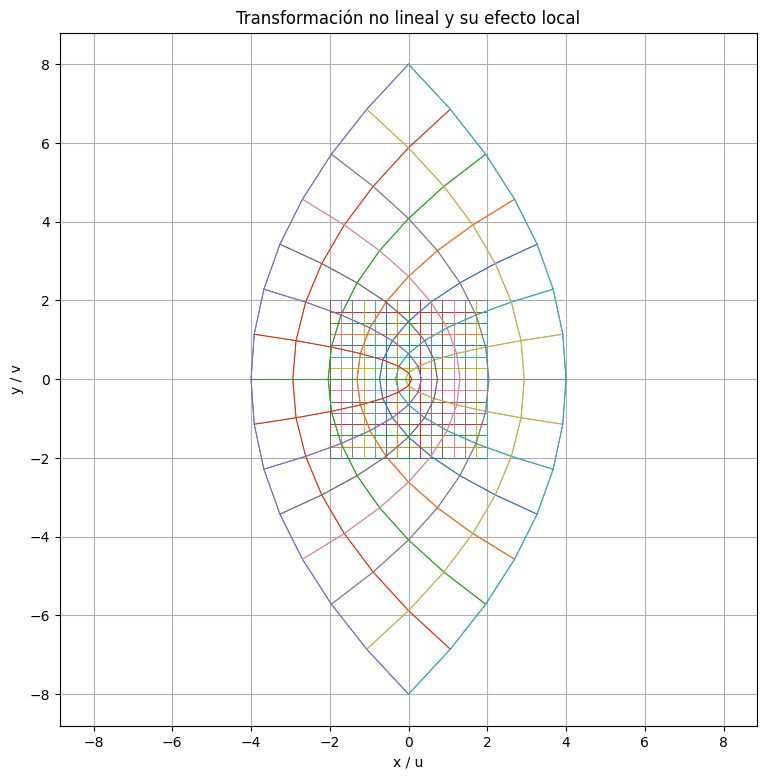

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Malla original
x = np.linspace(-2, 2, 15)
y = np.linspace(-2, 2, 15)

X, Y = np.meshgrid(x, y)

# Transformación
U = X**2 - Y**2
V = 2*X*Y

fig, ax = plt.subplots(figsize=(9, 9))

# Líneas originales
for i in range(len(x)):
    ax.plot(
        X[i, :],
        Y[i, :],
        linewidth=0.7
    )

for j in range(len(y)):
    ax.plot(
        X[:, j],
        Y[:, j],
        linewidth=0.7
    )

# Líneas transformadas
for i in range(len(x)):
    ax.plot(
        U[i, :],
        V[i, :],
        linewidth=0.7
    )

for j in range(len(y)):
    ax.plot(
        U[:, j],
        V[:, j],
        linewidth=0.7
    )

ax.set_xlabel("x / u")
ax.set_ylabel("y / v")
ax.set_title("Transformación no lineal y su efecto local")

ax.axis("equal")
ax.grid()

plt.show()

Aquí puedes observar una idea muy importante:

> Una función no lineal puede parecer una transformación lineal cuando la observamos suficientemente cerca de un punto.

Y el Jacobiano es precisamente esa transformación lineal local.

# 24. Jacobiano y cambio de volumen

Ahora aparece otra aplicación matemática muy importante.

Para:

$$
F:\mathbb R^n\rightarrow\mathbb R^n
$$

tenemos:

$$
J_F.
$$

El determinante:

$$
\boxed{
|\det J_F|
}
$$

mide el factor local de cambio de volumen.

En 2D:

$$
|\det J|
$$

mide aproximadamente el factor de cambio de **área**.

En 3D:

$$
|\det J|
$$

mide aproximadamente el factor de cambio de **volumen**.

Esto es fundamental para:

$$
\boxed{\text{cambio de variables en integrales}}
$$

# 25. Ejemplo: coordenadas polares

Recordemos:

$$
x=r\cos\theta
$$

$$
y=r\sin\theta
$$

El Jacobiano es:

$$
J=
\begin{bmatrix}
\frac{\partial x}{\partial r}
&
\frac{\partial x}{\partial\theta}
\\
\frac{\partial y}{\partial r}
&
\frac{\partial y}{\partial\theta}
\end{bmatrix}
$$

por lo tanto:

$$
J=
\begin{bmatrix}
\cos\theta&-r\sin\theta\\
\sin\theta&r\cos\theta
\end{bmatrix}.
$$

Su determinante:

$$
\det J
=
r\cos^2\theta+r\sin^2\theta
$$

$$
=r
$$

Así:

$$
\boxed{|\det J|=r}
$$

y por eso:

$$
\boxed{
dx\,dy=r\,dr\,d\theta
}
$$

Esto no es una fórmula arbitraria: **sale del Jacobiano**.

# 26. Jacobiano en SciML

Ahora puedes ver por qué este concepto es tan importante.

## ODE

$$
\frac{du}{dt}=F(u,t)
$$

requiere:

$$
J_F=\frac{\partial F}{\partial u}.
$$

## Newton

$$
F(x)=0
$$

requiere:

$$
J_F.
$$

## Estabilidad

$$
\dot u=F(u)
$$

requiere los eigenvalores de:

$$
J_F(u^*).
$$

## Sensibilidad

$$
\delta F\approx J_F\delta u.
$$

## Cambio de variables

$$
|\det J|.
$$


## PINNs

Una red:

$$
u_\theta(x,t)
$$

requiere derivadas:

$$
u_x,\quad u_t,\quad u_{xx}.
$$

## Autodiferenciación

Frameworks como PyTorch/JAX pueden calcular automáticamente Jacobianos y derivadas de funciones complejas.

# 27. Jacobiano de una red neuronal

Supongamos:

$$
F(x)=W_2\sigma(W_1x+b_1)+b_2
$$

donde:

* $(x)$ = entrada;
* $(W_1,W_2)$ = matrices;
* $(\sigma)$ = función de activación.

El Jacobiano respecto a $(x)$ involucra la regla de la cadena:

$$
\boxed{
J_F
=
W_2
D_\sigma
W_1
}
$$

donde:

$$
D_\sigma
$$

es una matriz diagonal con las derivadas de la activación.

Esta idea está detrás de **backpropagation**.

Por eso el Jacobiano conecta directamente:

$$
\boxed{
\text{cálculo multivariable}
\rightarrow
\text{regla de la cadena}
\rightarrow
\text{backpropagation}
}
$$

# 28. Jacobiano y regla de la cadena

Esta relación debes aprenderla muy bien.

Si:

$$
F:\mathbb R^n\rightarrow\mathbb R^m
$$

y:

$$
G:\mathbb R^p\rightarrow\mathbb R^n
$$

entonces:

$$
F\circ G:\mathbb R^p\rightarrow\mathbb R^m.
$$

El Jacobiano satisface:

$$
\boxed{
J_{F\circ G}(x)
=
J_F(G(x))J_G(x)
}
$$

Esto es la versión matricial de la regla de la cadena.

Y esta fórmula es fundamental para:

* redes neuronales;
* autodiff;
* PINNs;
* modelos diferenciables;
* simuladores diferenciables.

# 29. Un ejemplo pequeño de la regla de la cadena

Supongamos:

$$
G(x,y)=
\begin{bmatrix}
x^2+y\\
xy
\end{bmatrix}
$$

y:

$$
F(u,v)=
\begin{bmatrix}
u+v^2\\
e^u\sin v
\end{bmatrix}.
$$

Primero:

$$
J_G=
\begin{bmatrix}
2x&1\\
y&x
\end{bmatrix}.
$$

Y:

$$
J_F=
\begin{bmatrix}
1&2v\\
e^u\sin v&e^u\cos v
\end{bmatrix}.
$$

Entonces:

$$
\boxed{
J_{F\circ G}
=
J_F(G(x,y))J_G(x,y)
}
$$

No necesitas derivar toda la composición desde cero.

Esta propiedad será muy importante cuando estudies **autodiferenciación**.

# 30. Qué debes dominar antes de continuar

Para SciML, yo dividiría el dominio del Jacobiano en cuatro niveles.

### Nivel 1 — Cálculo

Debes poder calcular:

$$
J_F
$$

a mano.

### Nivel 2 — Geometría

Debes entender:

$$
\Delta F\approx J\Delta x.
$$

### Nivel 3 — Álgebra lineal

Debes entender:

$$
J\Delta x=b.
$$

y:

$$
\det J,\quad
\operatorname{rank}(J),\quad
\lambda(J).
$$

### Nivel 4 — SciML

Debes entender:

$$
J_F(u)
=
\frac{\partial F}{\partial u}
$$

en:

$$
\dot u=F(u,t).
$$

Y posteriormente:

$$
\boxed{
J
\rightarrow
\text{Newton}
\rightarrow
\text{estabilidad}
\rightarrow
\text{sensitivity}
\rightarrow
\text{autodiff}
\rightarrow
\text{SciML}
}
$$

# 31. Resumen definitivo


Si tienes:

$$
F:\mathbb R^n\rightarrow\mathbb R^m
$$

entonces:

$$
\boxed{
J_F\in\mathbb R^{m\times n}
}
$$

y:

$$
\boxed{
(J_F)_{ij}
=
\frac{\partial F_i}{\partial x_j}
}
$$

El Jacobiano permite aproximar:

$$
\boxed{
F(x+\Delta x)
\approx
F(x)+J_F(x)\Delta x
}
$$

Por tanto:

$$
\boxed{
\Delta F\approx J_F\Delta x
}
$$

Para sistemas no lineales:

$$
\boxed{
J_F(x)\Delta x=-F(x)
}
$$

es el corazón del método de Newton.

Para sistemas dinámicos:

$$
\boxed{
\dot x=F(x)
}
$$

el Jacobiano:

$$
\boxed{
J_F(x)
}
$$

describe la dinámica local.

En un equilibrio:

$$
F(x^*)=0
$$

tenemos:

$$
\boxed{
\dot{\delta x}
\approx
J_F(x^*)\delta x
}
$$

y sus eigenvalores permiten estudiar estabilidad.

Y para SciML, la cadena que debes tener grabada es:

```text
DERIVADAS PARCIALES
        ↓
     GRADIENTE
        ↓
    JACOBIANO
        ↓
REGLA DE LA CADENA
        ↓
APROXIMACIÓN LINEAL
        ↓
 ┌──────┼─────────┬───────────┐
 ↓      ↓         ↓           ↓
Newton ODE     Sensibilidad  Autodiff
 ↓      ↓         ↓           ↓
 ↓   Estabilidad  ↓        Neural Nets
 └──────┴─────────┴───────────┘
                ↓
              SciML
                ↓
       PINNs / Neural ODE
       Inverse Problems
       Parameter Estimation
       Differentiable Physics
```

**El siguiente paso matemático especialmente importante después del Jacobiano es la *diferenciabilidad y la aproximación de Taylor multivariable***, porque ahí vas a entender formalmente por qué

$$
F(x+\Delta x)\approx F(x)+J_F(x)\Delta x
$$

y después podrás pasar naturalmente a **Hessiano → optimización multivariable → Newton → ODE/PDE → autodiferenciación**, que es una ruta muy sólida hacia SciML.


| **Inicio**         | **atrás 2**                          | **Siguiente 4**                                    |
| ------------------ | ------------------------------------ | -------------------------------------------------- |
| [🏠](../README.md) | [⏪](./4_2_Derivadas_parciales.ipynb) | [⏩](./4_4_Hessiano.ipynb) |